# Chemical Reaction Yield Prediction
### A Machine Learning Assignment for Undergraduate Engineering Students

---

## Section 1: Problem Statement

In organic chemistry and pharmaceutical manufacturing, chemical reactions are conducted to synthesize target molecules from starting materials. A classic example is the **Claisen rearrangement** reaction, an important organic transformation where an allyl vinyl ether (or allyl aryl ether) rearranges into an isomerized product.

### The Challenge
Traditionally, discovering the optimal reaction conditions (such as temperature, residence time in a continuous flow reactor, and solvent systems) requires dozens of expensive, time-consuming laboratory experiments. 

### The Machine Learning Objective
The goal of this assignment is to train a simple **Artificial Neural Network (ANN)** to predict the **Yield (%)** of the reaction directly from accessible process conditions:
1. **Temperature** (°C)
2. **Residence Time** (minutes spent inside the reactor)
3. **Solvent A Name** (primary solvent)
4. **Solvent B Name** (secondary solvent)
5. **Solvent B Fraction** (`SolventB%`, proportion of secondary solvent in the mixture)

### What the Model Produces
Given these 5 operational inputs, the trained model outputs a single continuous numerical value: the predicted **Chemical Reaction Yield (%)**. This allows chemical engineers to simulate and screen reaction conditions before conducting experiments in the laboratory.


---
## Section 2: Import Libraries

We import standard, beginner-friendly Python libraries required for data analysis, preprocessing, neural network modeling, and evaluation.
- **Pandas**: Used for loading CSV data, inspecting tabular structures, and manipulating dataframes.
- **NumPy**: Used for mathematical operations and multidimensional array manipulations.
- **Matplotlib**: A standard plotting library used to create visualizations such as histograms, scatter plots, and training loss curves.
- **Scikit-learn**: Provides tools for data preprocessing (`StandardScaler`, `OneHotEncoder`, `ColumnTransformer`), splitting datasets (`train_test_split`), and evaluation metrics (`MAE`, `RMSE`, `R2`).
- **TensorFlow / Keras**: Used to define, compile, train, and evaluate our Artificial Neural Network.
- **Joblib & OS**: Used for saving the fitted preprocessor object and handling file paths.


In [1]:
# Import essential libraries
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn tools for data splitting, preprocessing, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# TensorFlow and Keras for deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seeds for reproducible results
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


---
## Section 3: Load the Dataset

We load the primary experimental dataset `catechol_full_data_yields.csv` located in the `data/` folder.

### Core Terminology for Machine Learning Beginners:
- **Row (Sample / Instance)**: Represents a single experimental run conducted under specific reactor conditions.
- **Column**: A recorded variable or measurement associated with each experiment.
- **Feature (Input $X$)**: The independent variables fed into the model to make predictions (e.g., Temperature, Residence Time, Solvents).
- **Target (Output $y$)**: The dependent variable the model learns to predict (Chemical Yield %).


In [2]:
# Detect base directory (supports running from root or from within training/)
base_dir = ".." if os.path.exists(os.path.join("..", "data")) else "."

# Load the experimental dataset
data_path = os.path.join(base_dir, "data", "catechol_full_data_yields.csv")
df = pd.read_csv(data_path)

# Display dataset dimensions (rows, columns)
print("Dataset Shape (Rows, Columns):", df.shape)

Dataset Shape (Rows, Columns): (1227, 19)


In [3]:
# Display the first 5 rows of the dataset
df.head()


,EXP NUM,SOLVENT A NAME,SOLVENT B NAME,SolventB%,Residence Time,Temperature,SM,Product 2,Product 3,SM SMILES,Product 2 SMILES,Product 3 SMILES,SOLVENT A SMILES,SOLVENT B SMILES,SOLVENT A Ratio,SOLVENT B Ratio,Reaction SMILES A,Reaction SMILES B,RAMP NUM
0,0,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,2.001019,175.0,0.903118,0.000000,0.000000,C=CCOC1=C(OCC=C)C=CC=C1,OC1=C(O)C(CC=C)=CC=C1CC=C,OC1=C(O)C(CC=C)=C(CC=C)C=C1,CO,OCCO,[1.0],[1.0],C=CCOC1=C(OCC=C)C=CC=C1.CO>>OC1=C(O)C(CC=C)=CC...,C=CCOC1=C(OCC=C)C=CC=C1.OCCO>>OC1=C(O)C(CC=C)=...,0
1,0,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,3.978167,175.0,0.898313,0.000000,0.000000,C=CCOC1=C(OCC=C)C=CC=C1,OC1=C(O)C(CC=C)=CC=C1CC=C,OC1=C(O)C(CC=C)=C(CC=C)C=C1,CO,OCCO,[1.0],[1.0],C=CCOC1=C(OCC=C)C=CC=C1.CO>>OC1=C(O)C(CC=C)=CC...,C=CCOC1=C(OCC=C)C=CC=C1.OCCO>>OC1=C(O)C(CC=C)=...,0
2,0,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,7.011797,175.0,0.897077,0.006710,0.005429,C=CCOC1=C(OCC=C)C=CC=C1,OC1=C(O)C(CC=C)=CC=C1CC=C,OC1=C(O)C(CC=C)=C(CC=C)C=C1,CO,OCCO,[1.0],[1.0],C=CCOC1=C(OCC=C)C=CC=C1.CO>>OC1=C(O)C(CC=C)=CC...,C=CCOC1=C(OCC=C)C=CC=C1.OCCO>>OC1=C(O)C(CC=C)=...,0
3,0,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,10.031130,175.0,0.876802,0.014084,0.010995,C=CCOC1=C(OCC=C)C=CC=C1,OC1=C(O)C(CC=C)=CC=C1CC=C,OC1=C(O)C(CC=C)=C(CC=C)C=C1,CO,OCCO,[1.0],[1.0],C=CCOC1=C(OCC=C)C=CC=C1.CO>>OC1=C(O)C(CC=C)=CC...,C=CCOC1=C(OCC=C)C=CC=C1.OCCO>>OC1=C(O)C(CC=C)=...,0
4,0,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,13.079227,175.0,0.857585,0.019298,0.013467,C=CCOC1=C(OCC=C)C=CC=C1,OC1=C(O)C(CC=C)=CC=C1CC=C,OC1=C(O)C(CC=C)=C(CC=C)C=C1,CO,OCCO,[1.0],[1.0],C=CCOC1=C(OCC=C)C=CC=C1.CO>>OC1=C(O)C(CC=C)=CC...,C=CCOC1=C(OCC=C)C=CC=C1.OCCO>>OC1=C(O)C(CC=C)=...,0


In [4]:
# Display column names, non-null counts, and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1227 entries, 0 to 1226
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EXP NUM            1227 non-null   int64  
 1   SOLVENT A NAME     1227 non-null   str    
 2   SOLVENT B NAME     1227 non-null   str    
 3   SolventB%          1227 non-null   float64
 4   Residence Time     1227 non-null   float64
 5   Temperature        1227 non-null   float64
 6   SM                 1227 non-null   float64
 7   Product 2          1227 non-null   float64
 8   Product 3          1227 non-null   float64
 9   SM SMILES          1227 non-null   str    
 10  Product 2 SMILES   1227 non-null   str    
 11  Product 3 SMILES   1227 non-null   str    
 12  SOLVENT A SMILES   1227 non-null   str    
 13  SOLVENT B SMILES   1227 non-null   str    
 14  SOLVENT A Ratio    1227 non-null   str    
 15  SOLVENT B Ratio    1227 non-null   str    
 16  Reaction SMILES A  1227 non-null   

In [5]:
# Display basic summary statistics of numerical columns
df.describe()


,EXP NUM,SolventB%,Residence Time,Temperature,SM,Product 2,Product 3,RAMP NUM
count,1227.000000,1227.000000,1227.000000,1227.000000,1227.000000,1227.000000,1227.000000,1227.000000
mean,4.762021,0.435865,13.726828,200.937287,0.495178,0.164626,0.143668,43.436838
std,3.214784,0.400336,3.280033,23.118608,0.379425,0.153467,0.145779,25.468079
min,0.000000,0.000000,2.001019,175.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,14.988550,175.000000,0.068573,0.012723,0.012260,21.000000
50%,5.000000,0.330153,15.000393,200.000000,0.606454,0.117330,0.094413,43.000000
75%,7.000000,0.858481,15.017208,225.000000,0.877448,0.308649,0.254630,66.000000
max,12.000000,1.000000,15.017208,225.000000,1.083254,0.463632,0.533768,86.000000


---
## Section 4: Basic Data Exploration

Before training a model, we inspect the data for missing values and duplicates, and plot basic graphs to understand the underlying distributions and physical trends.


In [6]:
# Check for missing values across all columns
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found in the entire dataset!")

# Check for duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows in the full dataset: {duplicate_count}")


Missing values per column:
No missing values found in the entire dataset!
Number of duplicate rows in the full dataset: 0


### Visualizing Key Relationships
Let us plot:
1. **Histogram of Reaction Yield**: Helps us observe the spread of yield values (e.g., whether the reactions mostly had low, medium, or high yields).
2. **Temperature vs. Reaction Yield**: Helps us observe how thermal energy affects reaction completion.
3. **Residence Time vs. Reaction Yield**: Helps us observe how time inside the reactor influences product formation.


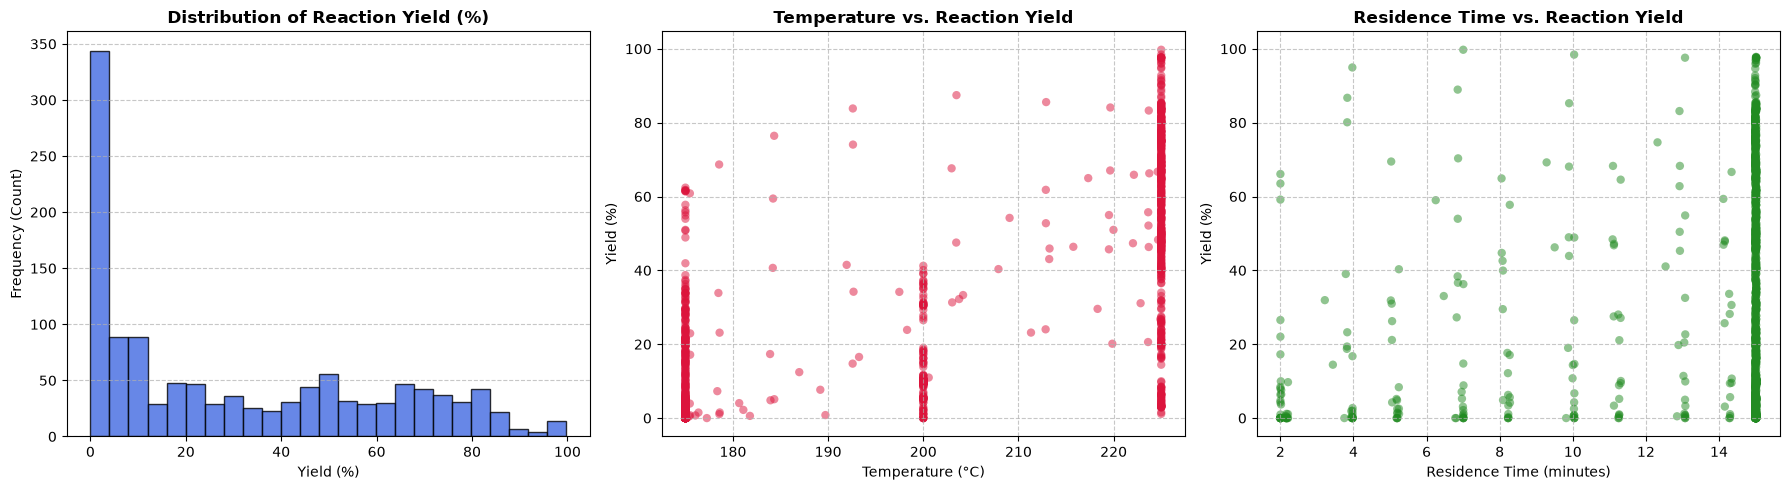

In [7]:
# First, calculate the experimental yield for visualization
# Formula: Yield (%) = (Product 2 + Product 3) * 100
df['Yield'] = (df['Product 2'] + df['Product 3']) * 100

# Set up a figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Histogram of Reaction Yield
axes[0].hist(df['Yield'], bins=25, color='royalblue', edgecolor='black', alpha=0.8)
axes[0].set_title("Distribution of Reaction Yield (%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Yield (%)")
axes[0].set_ylabel("Frequency (Count)")
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Temperature vs Yield
axes[1].scatter(df['Temperature'], df['Yield'], color='crimson', alpha=0.5, edgecolors='none')
axes[1].set_title("Temperature vs. Reaction Yield", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Yield (%)")
axes[1].grid(True, linestyle='--', alpha=0.7)

# Plot 3: Residence Time vs Yield
axes[2].scatter(df['Residence Time'], df['Yield'], color='forestgreen', alpha=0.5, edgecolors='none')
axes[2].set_title("Residence Time vs. Reaction Yield", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Residence Time (minutes)")
axes[2].set_ylabel("Yield (%)")
axes[2].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Observations from the Graphs:
- **Yield Distribution**: Reaction yields range from 0% up to approximately 99.7%, with an average yield around 30.8%. There is a cluster of near-zero yields (representing conditions where the reaction had barely begun) as well as moderate and high yield experiments.
- **Temperature Effect**: Reactions conducted at higher temperatures (e.g., 200°C–225°C) achieve higher maximum yields compared to runs at 175°C, consistent with the Arrhenius equation where reaction rates increase with temperature.
- **Residence Time Effect**: Longer residence times provide more opportunity for the starting materials to react, generally leading to higher yields.


---
## Section 5: Prepare the Target and Features

### 1. Target Definition
The Claisen rearrangement of catechol diallyl ether produces two desired isomeric products: **Product 2** and **Product 3**.
Following the assignment specifications, the total target yield is defined as:
$$\text{Yield} = (\text{Product 2} + \text{Product 3}) \times 100$$

### 2. Feature Selection
We select only pre-reaction operational parameters:
- `Temperature`
- `Residence Time`
- `SOLVENT A NAME`
- `SOLVENT B NAME`
- `SolventB%`

### Important Rule: Avoiding Data Leakage
We strictly do **NOT** include `Product 2`, `Product 3`, `SM` (remaining starting material), or conversion measurements as input features. In a real-world setting, these post-reaction values are unknown before running the experiment. Including them would "leak" the answer into the inputs and invalidate the machine learning model.


In [8]:
# Define input features and target column name
feature_cols = ['Temperature', 'Residence Time', 'SOLVENT A NAME', 'SOLVENT B NAME', 'SolventB%']
target_col = 'Yield'

# Verify that all required columns exist in the DataFrame
for col in feature_cols + ['Product 2', 'Product 3']:
    assert col in df.columns, f"Required column '{col}' not found in dataset!"

# Calculate target yield
df[target_col] = (df['Product 2'] + df['Product 3']) * 100

# Create a clean subset containing only features and target
dataset = df[feature_cols + [target_col]].copy()

# Check for any missing values in this subset
initial_rows = len(dataset)
dataset = dataset.dropna()
rows_removed = initial_rows - len(dataset)
print(f"Initial rows: {initial_rows}")
print(f"Rows removed due to missing values: {rows_removed}")
print(f"Remaining clean rows: {len(dataset)}")

# Display the first few rows of our prepared dataset
dataset.head()


Initial rows: 1227
Rows removed due to missing values: 0
Remaining clean rows: 1227


,Temperature,Residence Time,SOLVENT A NAME,SOLVENT B NAME,SolventB%,Yield
0,175.0,2.001019,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,0.000000
1,175.0,3.978167,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,0.000000
2,175.0,7.011797,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,1.213931
3,175.0,10.031130,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,2.507940
4,175.0,13.079227,Methanol,"Ethylene Glycol [1,2-Ethanediol]",0.0,3.276517


---
## Section 6: Prepare the Data for Machine Learning

Computers and neural networks cannot directly process text strings like `"Methanol"` or `"Cyclohexane"`. They require numerical representations.

### Preprocessing Strategy:
1. **One-Hot Encoding for Categorical Variables (`SOLVENT A NAME`, `SOLVENT B NAME`)**:
   - Converts each distinct solvent name into binary columns ($0$ or $1$).
   - For example, if Solvent A is "Methanol", its corresponding indicator column is $1$ while all other solvent columns are $0$.
   - This avoids implying any artificial numerical ordering between solvents.

2. **Standard Scaling for Numerical Variables (`Temperature`, `Residence Time`, `SolventB%`)**:
   - Neural networks train most stably when input features have comparable magnitudes.
   - `StandardScaler` standardizes features by subtracting the mean and dividing by the standard deviation:
     $$z = \frac{x - \mu}{\sigma}$$
   - This ensures a feature with larger values (like Temperature $\sim 200$) does not overpower a feature with smaller values (like SolventB% $\sim 0.5$).

3. **Train-Test Split**:
   - We divide the dataset into **80% training data** (used to teach the model) and **20% testing data** (held-out data used to evaluate how well the model generalizes to new experiments).
   - **Critical Practice**: The preprocessor is fitted **only on the training set** (`fit_transform`) and subsequently used to transform the test set (`transform`). This prevents information from the test set from leaking into the training pipeline.


In [9]:
# Separate inputs (X) and target (y)
X = dataset[feature_cols]
y = dataset[target_col]

# Split into 80% training set and 20% testing set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size:  {len(X_test)} samples")


Training set size: 981 samples
Testing set size:  246 samples


In [10]:
# Define which columns are numerical and which are categorical
numerical_cols = ['Temperature', 'Residence Time', 'SolventB%']
categorical_cols = ['SOLVENT A NAME', 'SOLVENT B NAME']

# Build a ColumnTransformer to apply the appropriate transformation to each column type
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Fit on training data ONLY, then transform both train and test sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original number of input features:", X_train.shape[1])
print("Processed feature dimensions (after one-hot encoding & scaling):", X_train_processed.shape[1])
print("Shape of X_train_processed:", X_train_processed.shape)
print("Shape of X_test_processed: ", X_test_processed.shape)


Original number of input features: 5
Processed feature dimensions (after one-hot encoding & scaling): 29
Shape of X_train_processed: (981, 29)
Shape of X_test_processed:  (246, 29)


---
## Section 7: Build the Artificial Neural Network (ANN)

An **Artificial Neural Network (ANN)** is a machine learning model inspired by biological neural circuits. It learns complex mathematical mappings between inputs and outputs by adjusting internal connection weights.

### Architecture for this Assignment:
1. **Input Layer**: Matches the dimensionality of our processed features (29 inputs: 3 scaled numerical values + 26 one-hot encoded solvent indicators).
2. **Hidden Layer (Dense, 16 neurons, ReLU activation)**:
   - Contains 16 artificial neurons. Each neuron computes a weighted sum of all inputs plus a bias term.
   - **ReLU (Rectified Linear Unit)** activation function, $f(x) = \max(0, x)$, introduces non-linearity. This enables the network to learn non-linear relationships (such as reaction kinetics and solvent effects) rather than simple linear trends.
3. **Output Layer (Dense, 1 neuron, Linear activation)**:
   - Produces a single continuous number: the predicted reaction yield (%).
   - Linear activation $f(x) = x$ allows the output to take any continuous real value.

### Training Configuration:
- **Loss Function: Mean Squared Error (MSE)**: Measures the average squared difference between predicted yields and actual yields. Penalizes larger mistakes more heavily.
- **Optimizer: Adam**: An efficient gradient-descent optimization algorithm that automatically adapts the learning rate for each weight during training.
- **Metric: MAE (Mean Absolute Error)**: Tracks the average error in actual yield percentage points.


In [11]:
# Define the small, beginner-friendly ANN architecture
input_dim = X_train_processed.shape[1]

model = keras.Sequential([
    layers.Input(shape=(input_dim,), name="Input_Layer"),
    layers.Dense(16, activation='relu', name="Hidden_Layer_1"),
    layers.Dense(1, activation='linear', name="Output_Layer")
], name="Chemical_Yield_Predictor_ANN")

# Compile the model with Adam optimizer and MSE loss
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss='mean_squared_error',
    metrics=['mae']
)

# Display the model architecture and parameter count
model.summary()


Model: "Chemical_Yield_Predictor_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

---
## Section 8: Train the Model

We train the model using `model.fit()`:
- **Epoch**: One complete pass through the entire training dataset. We train for 100 epochs.
- **Batch Size (32)**: The network updates its weights after evaluating 32 samples at a time.
- **Validation Split (10%)**: 10% of the training data is held aside during each epoch to monitor performance on unseen data and detect potential overfitting.

### What Decreasing Loss Means:
As training proceeds, the optimizer updates the weights to reduce the Mean Squared Error. A steadily decreasing loss indicates that the network is successfully learning to map reaction conditions to reaction yields.


In [12]:
# Train the ANN
history = model.fit(
    X_train_processed, 
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("\nModel training finished successfully!")


Epoch 1/100


 1/28 ━━━━━━━━━━━━━━━━━━━━ 10s 372ms/step - loss: 1221.8584 - mae: 22.0909

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1754.4589 - mae: 30.0526 - val_loss: 1702.5554 - val_mae: 29.3537


Epoch 2/100


 1/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1106.3740 - mae: 20.5409

...

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 20.9968 - mae: 2.9797 - val_loss: 23.8979 - val_mae: 3.3174


Epoch 100/100


 1/28 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 11.2474 - mae: 2.4683

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 20.9141 - mae: 2.9725 - val_loss: 23.4861 - val_mae: 3.2955



Model training finished successfully!


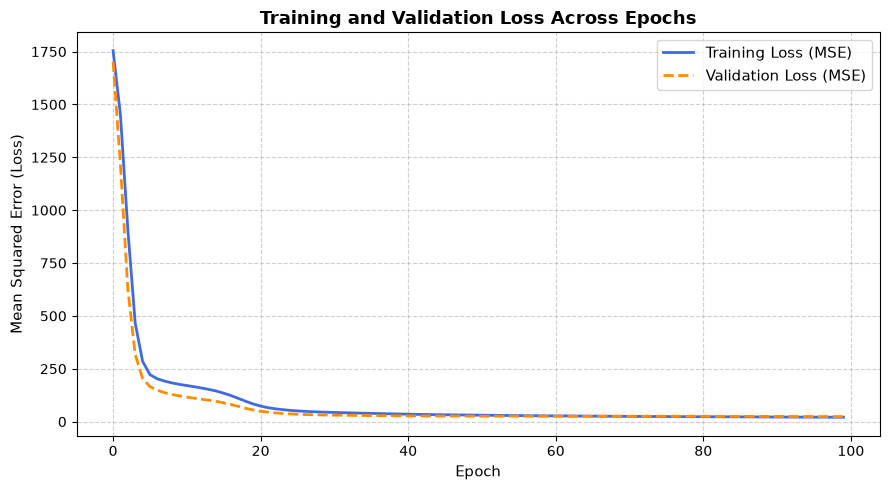

In [13]:
# Plot training and validation loss curves over epochs
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='royalblue', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='darkorange', linewidth=2, linestyle='--')

plt.title('Training and Validation Loss Across Epochs', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Mean Squared Error (Loss)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Interpreting the Loss Curve:
The loss drops sharply during the initial 20 epochs as the network learns major trends (such as the strong positive correlation between temperature/time and yield), then flattens out smoothly. The validation loss tracks the training loss closely without diverging upwards, demonstrating that our small model is not severely overfitting the training data.


---
## Section 9: Test and Evaluate

Now we evaluate the model on the held-out **test set** ($20\%$ of the data), which the model has never seen during training.

### Evaluation Metrics:
1. **Mean Absolute Error (MAE)**:
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   Represents the average error magnitude in percentage points of yield.
2. **Root Mean Squared Error (RMSE)**:
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
   Gives higher weight to larger errors.
3. **R-squared ($R^2$) Score**:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   Indicates the proportion of variance in the reaction yield explained by the model ($1.0$ is perfect; $0.0$ means the model performs no better than guessing the average yield).


In [14]:
# Generate predictions on the held-out test data
y_pred = model.predict(X_test_processed).flatten()

# Calculate performance metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=" * 45)
print("           TEST EVALUATION RESULTS           ")
print("=" * 45)
print(f"Mean Absolute Error (MAE) : {mae:.2f}%")
print(f"Root Mean Squared Error   : {rmse:.2f}%")
print(f"R-squared Score (R²)      : {r2:.4f}")
print("=" * 45)


1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 



           TEST EVALUATION RESULTS           
Mean Absolute Error (MAE) : 3.65%
Root Mean Squared Error   : 5.55%
R-squared Score (R²)      : 0.9640


In [15]:
# Display sample predictions side-by-side with actual test values
comparison_df = pd.DataFrame({
    'Actual Yield (%)': np.round(y_test.values[:10], 2),
    'Predicted Yield (%)': np.round(y_pred[:10], 2),
    'Absolute Error (%)': np.round(np.abs(y_test.values[:10] - y_pred[:10]), 2)
})
print("Sample Test Predictions (First 10 instances):")
comparison_df


Sample Test Predictions (First 10 instances):


,Actual Yield (%),Predicted Yield (%),Absolute Error (%)
0,63.42,65.129997,1.71
1,0.00,-2.080000,2.08
2,52.29,53.130001,0.84
3,0.00,-2.080000,2.08
4,96.91,96.720001,0.19
5,0.71,-2.070000,2.78
6,6.23,9.810000,3.58
7,16.75,15.120000,1.64
8,6.56,15.830000,9.27
9,78.63,84.739998,6.11


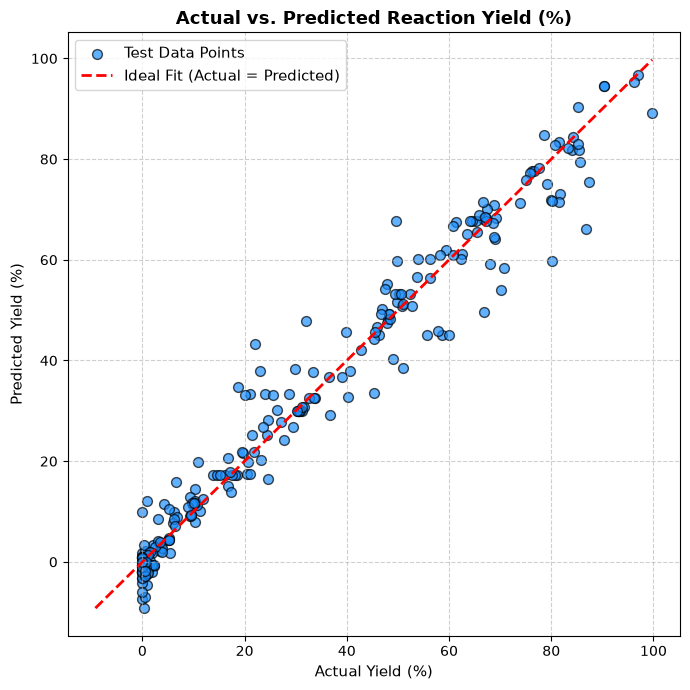

In [16]:
# Plot Actual vs. Predicted Yields with a 45-degree reference line
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, color='dodgerblue', edgecolors='black', alpha=0.7, s=50, label='Test Data Points')

# Ideal prediction diagonal (y = x)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (Actual = Predicted)')

plt.title("Actual vs. Predicted Reaction Yield (%)", fontsize=13, fontweight='bold')
plt.xlabel("Actual Yield (%)", fontsize=11)
plt.ylabel("Predicted Yield (%)", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Discussion of Results:
- Points clustering near the red dashed diagonal line indicate that the model captures the overall reaction progression well across varying temperatures and solvent systems.
- **Important Academic Note**: This random train-test split evaluates how well the network interpolates on held-out test conditions *within the solvent pairs present in the dataset*. It does **not** prove that the model can reliably extrapolate to brand-new, unseen chemical catalysts or entirely different solvent families not present in the training set.


---
## Section 10: Save the Model and Preprocessor

To build an interactive frontend (such as a Streamlit application), we must save two critical components:
1. **`ann_model.keras`**: The trained neural network weights and architecture.
2. **`preprocessor.joblib`**: The fitted `ColumnTransformer` containing the exact standard scaling parameters (means and standard deviations) and the one-hot categorical encoder categories.

### Why both are required:
When a user enters raw inputs in the frontend (e.g. Temperature = 190°C, Solvent A = "Methanol"), the neural network cannot read them directly. The saved preprocessor ensures that user inputs are scaled and one-hot encoded in the **exact same order and format** as the training data before being passed to the ANN.


In [17]:
# Detect base directory (supports running from root or from within training/)
base_dir = ".." if os.path.exists(os.path.join("..", "data")) else "."

# Ensure the models directory exists
models_dir = os.path.join(base_dir, "models")
os.makedirs(models_dir, exist_ok=True)

# Define file paths
model_path = os.path.join(models_dir, "ann_model.keras")
preprocessor_path = os.path.join(models_dir, "preprocessor.joblib")

# Save the Keras model
model.save(model_path)
print(f"Model successfully saved to: {model_path}")

# Save the Scikit-learn preprocessor
joblib.dump(preprocessor, preprocessor_path)
print(f"Preprocessor successfully saved to: {preprocessor_path}")

# Verify that both files exist on disk
print("Verification - Directory contents of 'models/':", os.listdir(models_dir))

Model successfully saved to: models\ann_model.keras
Preprocessor successfully saved to: models\preprocessor.joblib
Verification - Directory contents of 'models/': ['ann_model.keras', 'preprocessor.joblib']


---
## Section 11: Conclusion

### Summary of What We Built:
1. **Problem**: Predicted chemical reaction yield (%) for the Claisen rearrangement reaction using experimental continuous-flow data.
2. **Inputs**: Five key process variables: Temperature, Residence Time, Solvent A Name, Solvent B Name, and Solvent B Fraction.
3. **Preprocessing**: Applied standard scaling to numerical inputs and one-hot encoding to categorical solvent names using a Scikit-learn `ColumnTransformer`, fitted strictly on training data to prevent data leakage.
4. **Architecture**: Implemented a small, understandable Artificial Neural Network with one hidden layer of 16 ReLU neurons, trained with the Adam optimizer and Mean Squared Error loss.
5. **Evaluation**: Evaluated performance using MAE, RMSE, and $R^2$ on held-out test data, demonstrating that machine learning can effectively capture non-linear chemical reaction trends.
6. **Artifacts**: Saved both the trained ANN and the preprocessor so they can power an interactive Streamlit frontend.

### Limitations:
- **Scope of Data**: The model is trained on a specific reaction (catechol diallyl ether Claisen rearrangement) and 13 solvent pairs. It cannot predict yields for arbitrary chemical reactions or unrepresented solvent classes.
- **Physical Bounds**: Because the neural network uses a linear output neuron, under extreme input values it may mathematically predict values slightly below 0% or above 100%, requiring domain-level clamping in real applications.
- **Experimental Verification**: Model predictions serve as rapid screening estimates and must always be validated through physical experiments in the laboratory.


In [ ]:
# =====================================================
# EVALUATION GRAPHS & METRICS EXPORT
# =====================================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Detect base directory and ensure results directory exists
base_dir = ".." if os.path.exists(os.path.join("..", "data")) else "."
results_dir = os.path.join(base_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# 1. Save Training Loss Curve
plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'], label='Train Loss', color='royalblue')
plt.plot(history.history['val_loss'], label='Val Loss', color='darkorange', linestyle='--')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'training_loss_curve.png'), dpi=300)
plt.close()

# 2. Save Actual vs Predicted Scatter Plot
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='dodgerblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Ideal (y = x)')
plt.title('Actual vs Predicted Yield (%)')
plt.xlabel('Actual Yield (%)'); plt.ylabel('Predicted Yield (%)'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'actual_vs_predicted.png'), dpi=300)
plt.close()

# 3. Save Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, alpha=0.6, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual Plot (Errors vs Predicted)')
plt.xlabel('Predicted Yield (%)'); plt.ylabel('Residual (Actual - Predicted)'); plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'residual_plot.png'), dpi=300)
plt.close()

# 4. Calculate Metrics & Save Summary File
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

summary = f"""=====================================================
MODEL EVALUATION RESULTS & PARAMETERS
=====================================================
Mean Squared Error (MSE)      : {mse:.4f}
Mean Absolute Error (MAE)     : {mae:.4f}%
R-squared Score (R2)          : {r2:.4f}

MODEL ARCHITECTURE & TRAINING PARAMETERS:
- Model Type                  : Artificial Neural Network (ANN)
- Hidden Layers               : 1 Dense Layer (16 neurons, ReLU)
- Output Layer                : 1 Dense Layer (1 neuron, Linear)
- Optimizer                   : Adam (learning rate = 0.01)
- Loss Function               : Mean Squared Error (MSE)
- Training Epochs             : 100
- Batch Size                  : 32
- Train/Test Split            : 80% Train (981 samples) / 20% Test (246 samples)
=====================================================
"""

output_txt_path = os.path.join(results_dir, 'test_results_and_parameters.txt')
with open(output_txt_path, 'w') as f:
    f.write(summary)

print(f"Evaluation graphs and {output_txt_path} saved successfully!")
print(f"MSE: {mse:.4f} | MAE: {mae:.4f}% | R2: {r2:.4f}")